In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('data/real_estate_price_size.csv')

In [3]:
print(f"Shape: {df.shape}")

df.head()

Shape: (100, 2)


,price,size
0,234314.144,643.09
1,228581.528,656.22
2,281626.336,487.29
3,401255.608,1504.75
4,458674.256,1275.46


In [4]:
# Train test split
# from sklearn.model_selection import train_test_split
# We will make a simple one on our own for 80/20 split
train_size = int(df.shape[0] * 0.8)
X_train, y_train = df.loc[:train_size, 'size'], df.loc[:train_size, 'price']
X_test, y_test = df.loc[train_size:, 'size'], df.loc[train_size:, 'price']


In [5]:
# Standardize the inputs
X_mean, y_mean = X_train.mean(), y_train.mean()
X_std, y_std = X_train.std(), y_train.std()

X_train_scaled, y_train_scaled = ((X_train - X_mean) / X_std), ((y_train - y_mean) / y_std)
X_test_scaled = ((X_test - X_mean) / X_std)

In [6]:
# Define cost function
def costFn(X, y, w, b, alpha):
    y_pred = w * X + b

    error = y_pred - y

    grad_w = (1 / (len(X))) * sum(error * X)
    grad_b = (1 / (len(X))) * sum(error)

    w =  w - alpha * grad_w
    b =  b - alpha * grad_b

    cost = (1 / (2 * len(X))) * sum(error ** 2)

    return w, b, cost

In [7]:
def predict(X, w, b):
    return w * X + b

In [8]:
w = b = best_w = best_b = 0
minCost = np.inf
alpha = 0.1
epoch = 100000
bestEpoch = 0
error_hist = []
prevCost = np.inf
for i in range(epoch):
    w, b, cost = costFn(X_train_scaled, y_train_scaled, w, b, alpha)
    error_hist.append(cost)
    if cost < minCost:
        best_w = w
        best_b = b
        minCost = cost
        bestEpoch = i
    print(f"Epoch: {i}; w: {w}; b: {b}; Cost: {cost}")
    # Early Stopping
    if abs(prevCost - cost) < 1e-12:
        break
    prevCost = cost

print(f"BestEpoch: {bestEpoch}; Best w: {best_w}; Best b: {best_b}; Min Cost: {minCost}")

Epoch: 0; w: 0.08560564592241447; b: 5.674473236973022e-17; Cost: 0.49382716049382697
Epoch: 1; w: 0.1627564132352078; b: 1.16230756158288e-16; Cost: 0.4241628210787501
Epoch: 2; w: 0.23228735167760173; b: 1.7462026337931475e-16; Cost: 0.3675797903299399
Epoch: 3; w: 0.2949510369405; b: 2.3026847918151394e-16; Cost: 0.3216217091135994
Epoch: 4; w: 0.3514257162515071; b: 2.8591669498371315e-16; Cost: 0.2842934642116211
Epoch: 5; w: 0.40232264945772334; b: 3.399201359346158e-16; Cost: 0.2539745772915415
Epoch: 6; w: 0.44819272506332564; b: 3.9173054375045646e-16; Cost: 0.2293488573712392
Epoch: 7; w: 0.4895324228313376; b: 4.399772727218213e-16; Cost: 0.20934726288026356
Epoch: 8; w: 0.5267891874864594; b: 4.865792268418896e-16; Cost: 0.19310149286922726
Epoch: 9; w: 0.5603662716818162; b: 5.307140186850131e-16; Cost: 0.1799062926880335
Epoch: 10; w: 0.590627100648002; b: 5.721075191093091e-16; Cost: 0.16918883776262864
Epoch: 11; w: 0.6178992057656755; b: 6.12404502966074e-16; Cost: 0.1

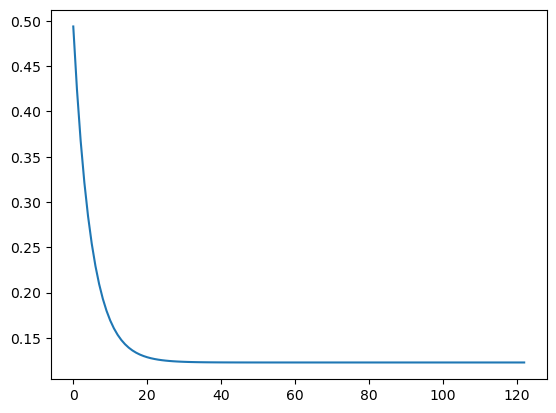

In [9]:
import matplotlib.pyplot as plt

plt.plot(error_hist)


In [10]:
y_pred_scaled = predict(X_test_scaled, best_w, best_b)

In [11]:
y_pred = y_pred_scaled * y_std + y_mean

In [12]:
mse = ((y_pred - y_test) ** 2).mean()
rmse = np.sqrt(mse)

print(f"MSE: {mse}; RMSE: {rmse}")

MSE: 1483797811.007353; RMSE: 38520.09619675622
